## 1. Import libraries and configure the inference environment

In [1]:
from    typing  import  Sequence
from    itertools   import  product

from    tqdm.notebook   import  tqdm
from    time            import  perf_counter

import  torch
from    torch.utils.data                import  DataLoader

from    deep_numerical.utils            import  GaussianNormalizer, relative_error, sec_to_hms
from    deep_numerical.neural.utils     import  count_parameters
from    deep_numerical.neural.parameterized_op  import  ModifiedFNO, PFNO, ModifiedRFNO, PRFNO
import  matplotlib.pyplot               as  plt

from    loader      import  NormKeys, HistKeys
from    loader      import  path_base
from    loader      import  load_model_args, load_model_data
from    dataset     import  nonparametric_dataset, parametric_dataset
from    plot        import  *


DEVICE: torch.device = torch.device("cuda:1")

list_max_freq   = [8]
list_seed       = [2]
max_freq        = list_max_freq[0]
seed            = list_seed[0]

res_v = 2**6


print(f"Inference for [max_freq{max_freq:02d}__seed{seed}]")

Inference for [max_freq08__seed2]


## 2. Instantiate the trained operators and normalizers

### 2-1. Load data (trained parameters, normalizers, and training histories)

In [2]:
model_data_fno      = load_model_data("FNO3D-param", max_freq, seed)
model_data_pfno     = load_model_data("PFNO3D-param", max_freq, seed)
model_data_rfno     = load_model_data("RFNO3D-param", max_freq, seed)
model_data_prfno    = load_model_data("PRFNO3D-param", max_freq, seed)

### 2-2. Load training history

In [3]:
history_fno:    dict[HistKeys, float|list[float]] = model_data_fno["train_history"]
history_pfno:   dict[HistKeys, float|list[float]] = model_data_pfno["train_history"]
history_rfno:   dict[HistKeys, float|list[float]] = model_data_rfno["train_history"]
history_prfno:  dict[HistKeys, float|list[float]] = model_data_prfno["train_history"]

hists = [history_fno, history_pfno, history_rfno, history_prfno]
labels = ["FNO", "PFNO", "RFNO", "PRFNO"]
print("Successfully loaded training histories.")

Successfully loaded training histories.


In [4]:
for hist, label in zip(hists, labels):
    print(f"Training time for {label}\n>>> {sec_to_hms(int(hist['train_time']))}")

Training time for FNO
>>> 1 day, 18:41:47
Training time for PFNO
>>> 2 days, 5:02:55
Training time for RFNO
>>> 1 day, 18:54:10
Training time for PRFNO
>>> 2 days, 5:15:25


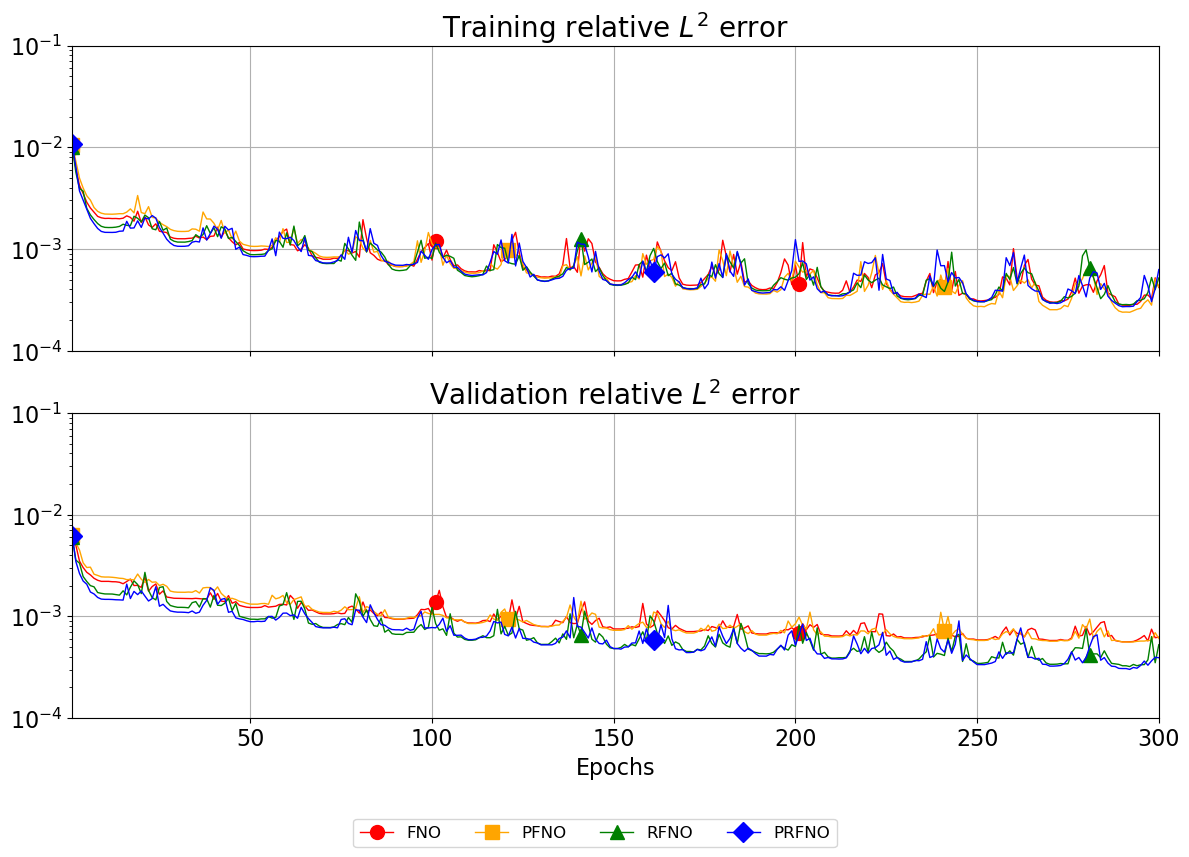

In [5]:
fig: plt.Figure
axes: Sequence[plt.Axes]
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for hist, color, label, marker, markevery in zip(hists, LIST_COLOR_1, labels, LIST_MARKER, LIST_MARKEVERY):
    assert len(hist['train_rel_error'])==len(hist['train_rel_error_cons'])
    assert len(hist['train_rel_error_cons'])==len(hist['val_rel_error'])
    assert len(hist['val_rel_error'])==len(hist['val_rel_error_cons'])
    num_epochs = len(hist['train_rel_error'])
    _list_epochs = list(range(1, 1+num_epochs))
    axes[0].set_title("Training relative $L^2$ error", fontsize=SIZE_TITLE)
    axes[0].plot(
        _list_epochs, hist['train_rel_error'],
        linewidth=LINEWIDTH_1, color=color,
        marker=marker, markevery=markevery, markersize=MARKERSIZE,
        label=label,
    )
    axes[1].set_title("Validation relative $L^2$ error", fontsize=SIZE_TITLE)
    axes[1].plot(
        _list_epochs, hist['val_rel_error'],
        linewidth=LINEWIDTH_1, color=color,
        marker=marker, markevery=markevery, markersize=MARKERSIZE,
    )

for ax in axes:
    ax.set_xlim(min(_list_epochs), max(_list_epochs))
    ax.set_ylim(1e-4, 1e-1)
    ax.set_yscale('log')
    ax.tick_params(axis='both', which='major', labelsize=SIZE_TICK)
    ax.grid(True)
axes[-1].set_xlabel('Epochs', fontsize=SIZE_LABEL)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02), fontsize=SIZE_LEGEND, ncols=4)
fig.tight_layout()
fig.savefig(f"train_validation_loss__[max_freq{max_freq:02d}__seed{seed}].pdf", bbox_inches='tight')

### 2-3. Load trained operators

In [6]:
model_fno   = ModifiedFNO(**load_model_args("FNO3D-param", max_freq))
model_pfno  = PFNO(**load_model_args("PFNO3D-param", max_freq))
model_rfno  = ModifiedRFNO(**load_model_args("RFNO3D-param", max_freq))
model_prfno = PRFNO(**load_model_args("PRFNO3D-param", max_freq))

model_fno.load_state_dict(  model_data_fno["state_dict"])
model_pfno.load_state_dict( model_data_pfno["state_dict"])
model_rfno.load_state_dict( model_data_rfno["state_dict"])
model_prfno.load_state_dict(model_data_prfno["state_dict"])
model_fno.to(DEVICE)
model_pfno.to(DEVICE)
model_rfno.to(DEVICE)
model_prfno.to(DEVICE)
model_fno.eval()
model_pfno.eval()
model_rfno.eval()
model_prfno.eval()
print(f"Successfully loaded models.")

Successfully loaded models.


In [7]:
for _model_key, _model in zip(labels, [model_fno, model_pfno, model_rfno, model_prfno]):
    num_params = count_parameters(_model)
    print(f"Number of parameters in {_model_key}2D-param\n>>> {num_params}")

Number of parameters in FNO2D-param
>>> 21354273
Number of parameters in PFNO2D-param
>>> 32084417
Number of parameters in RFNO2D-param
>>> 1627297
Number of parameters in PRFNO2D-param
>>> 2494273


### 2-4. Load normalizers

In [8]:
norm_fno:   dict[NormKeys, GaussianNormalizer] = model_data_fno["normalizer"]
norm_pfno:  dict[NormKeys, GaussianNormalizer] = model_data_pfno["normalizer"]
norm_rfno:  dict[NormKeys, GaussianNormalizer] = model_data_rfno["normalizer"]
norm_prfno: dict[NormKeys, GaussianNormalizer] = model_data_prfno["normalizer"]
print(f"Successfully loaded normalizers.")

Successfully loaded normalizers.


## 3. Conduct inference

### 3-1. Construct dataloader

In [9]:
path_data = path_base / "datasets" / "test" / f"Boltzmann_3D__coeff7.96e-02__res_t051_v{res_v:03d}"
assert path_data.exists(), f"The data path {path_data} does not exist."
list_alpha = torch.arange(21)*0.05
part_start, part_end = 1, 1

data, params = [], []
generation_time = 0.0
files = sorted(path_data.glob("alpha*.pth"))
alpha_and_part = list(product(list_alpha, range(part_start, part_end+1)))
for alpha, part in tqdm(alpha_and_part):
    if res_v>2**5:
        file = path_data / f"alpha{alpha:.2f}__part{part:03d}.pth"
    else:
        file = path_data / f"alpha{alpha:.2f}__part{part:02d}.pth"
    try:
        f = torch.load(file, weights_only=False, map_location='cpu')
    except FileNotFoundError:
        print(f"File not found: {file}")
        continue
    data.append(f['data'])         # (num_instances, res_t, 1, 1, res, res, 1)
    params.append(f['vhs_alpha']*torch.ones(f['data'].size(0), 1))     # float
    generation_time += f['elapsed_time']
data    = torch.cat(data, dim=0)               # (num_total_instances, res_t, 1, 1, res, res, 1)
params  = torch.cat(params, dim=0)           # (num_total_instances, 1)
num_inst, res_t, res_v = data.size(0), data.size(1), data.size(-2)
data    = data.view(num_inst, res_t, res_v, res_v, res_v, 1)
data    = data.type(torch.float)
params  = params.type(torch.float)

print(f"Successfully loaded dataset with {num_inst} instances.")
print(f"Time for generating dataset\n>>> {sec_to_hms(int(generation_time))}")

  0%|          | 0/21 [00:00<?, ?it/s]

Successfully loaded dataset with 21 instances.
Time for generating dataset
>>> 0:21:30


In [10]:
BATCH_SIZE = 2**6 if res_v==2**6 else 2**4 if res_v==2**7 else None
dataloader_fno  = DataLoader(nonparametric_dataset(data, params, norm_fno), batch_size=BATCH_SIZE, shuffle=False)
dataloader_pfno = DataLoader(parametric_dataset(data, params, norm_pfno), batch_size=BATCH_SIZE, shuffle=False)
dataloader_rfno = DataLoader(nonparametric_dataset(data, params, norm_rfno), batch_size=BATCH_SIZE, shuffle=False)
dataloader_prfno = DataLoader(parametric_dataset(data, params, norm_prfno), batch_size=BATCH_SIZE, shuffle=False)
print(f"Successfully prepared dataloaders.")

Successfully prepared dataloaders.


### 3-2. Compute the trajectories on the test set

In [11]:
for v in norm_fno.values():   v.to(DEVICE)
for v in norm_pfno.values():  v.to(DEVICE)
for v in norm_rfno.values():  v.to(DEVICE)
for v in norm_prfno.values(): v.to(DEVICE)

FNO

In [12]:
pred_fno = []
inference_time_fno = perf_counter()

with torch.inference_mode():
    model_preds = []
    traj:   torch.Tensor
    alphas: torch.Tensor
    for traj, alphas in tqdm(dataloader_fno, desc="FNO Inference"):
        traj    = traj.to(DEVICE)
        alphas  = alphas.to(DEVICE)
        pred    = traj[:, 0]    # The initial condition of shape `(batch_size, res, res, 1)`
        # Save the initial condition
        batch_pred = [norm_fno['data'].decode(pred).cpu()]
        # Compute the trajectory
        model_fno.update_register(res_v)
        for t in range(1, res_t):
            pred = model_fno.forward(pred, alphas)
            batch_pred.append(norm_fno['data'].decode(pred).cpu())
        batch_pred = torch.stack(batch_pred, dim=1)   # (batch_size, res_t, res, res, 1)
        model_preds.append(batch_pred)
    pred_fno = torch.cat(model_preds, dim=0)   # (num_inst, res_t, res, res, 1)

inference_time_fno = perf_counter() - inference_time_fno
torch.cuda.empty_cache()
print(f"FNO Inference time: {inference_time_fno:.2f} seconds.")

FNO Inference:   0%|          | 0/1 [00:00<?, ?it/s]

FNO Inference time: 37.21 seconds.


PFNO

In [14]:
pred_pfno = []
inference_time_pfno = perf_counter()

with torch.inference_mode():
    model_preds = []
    traj:   torch.Tensor
    alphas: torch.Tensor
    for traj, alphas in tqdm(dataloader_pfno, desc="PFNO Inference"):
        traj    = traj.to(DEVICE)
        alphas  = alphas.to(DEVICE)
        pred    = traj[:, 0]    # The initial condition of shape `(batch_size, res, res, 1)`
        # Save the initial condition
        batch_pred = [norm_pfno['data'].decode(pred).cpu()]
        # Compute the trajectory
        model_pfno.update_register(res_v, alphas)
        for t in range(1, res_t):
            pred = model_pfno.forward(pred, alphas)
            batch_pred.append(norm_pfno['data'].decode(pred).cpu())
        batch_pred = torch.stack(batch_pred, dim=1)   # (batch_size, res_t, res, res, 1)
        model_preds.append(batch_pred)
    pred_pfno = torch.cat(model_preds, dim=0)   # (num_inst, res_t, res, res, 1)

inference_time_pfno = perf_counter() - inference_time_pfno
torch.cuda.empty_cache()
print(f"PFNO Inference time: {inference_time_pfno:.2f} seconds.")

PFNO Inference:   0%|          | 0/1 [00:00<?, ?it/s]

PFNO Inference time: 44.42 seconds.


RFNO

In [15]:
pred_rfno = []
inference_time_rfno = perf_counter()

with torch.inference_mode():
    model_preds = []
    traj:   torch.Tensor
    alphas: torch.Tensor
    for traj, alphas in tqdm(dataloader_rfno, desc="RFNO Inference"):
        traj    = traj.to(DEVICE)
        alphas  = alphas.to(DEVICE)
        pred    = traj[:, 0]    # The initial condition of shape `(batch_size, res, res, 1)`
        # Save the initial condition
        batch_pred = [norm_rfno['data'].decode(pred).cpu()]
        # Compute the trajectory
        model_rfno.update_register(res_v)
        for t in range(1, res_t):
            pred = model_rfno.forward(pred, alphas)
            batch_pred.append(norm_rfno['data'].decode(pred).cpu())
        batch_pred = torch.stack(batch_pred, dim=1)   # (batch_size, res_t, res, res, 1)
        model_preds.append(batch_pred)
    pred_rfno = torch.cat(model_preds, dim=0)   # (num_inst, res_t, res, res, 1)

inference_time_rfno = perf_counter() - inference_time_rfno
torch.cuda.empty_cache()
print(f"RFNO Inference time: {inference_time_rfno:.2f} seconds.")

RFNO Inference:   0%|          | 0/1 [00:00<?, ?it/s]

RFNO Inference time: 36.98 seconds.


PRFNO

In [16]:
pred_prfno = []
inference_time_prfno = perf_counter()

with torch.inference_mode():
    model_preds = []
    traj:   torch.Tensor
    alphas: torch.Tensor
    for traj, alphas in tqdm(dataloader_prfno, desc="PRFNO Inference"):
        traj    = traj.to(DEVICE)
        alphas  = alphas.to(DEVICE)
        pred    = traj[:, 0]    # The initial condition of shape `(batch_size, res, res, 1)`
        # Save the initial condition
        batch_pred = [norm_prfno['data'].decode(pred).cpu()]
        # Compute the trajectory
        model_prfno.update_register(res_v, alphas)
        for t in range(1, res_t):
            pred = model_prfno.forward(pred, alphas)
            batch_pred.append(norm_prfno['data'].decode(pred).cpu())
        batch_pred = torch.stack(batch_pred, dim=1)   # (batch_size, res_t, res, res, 1)
        model_preds.append(batch_pred)
    pred_prfno = torch.cat(model_preds, dim=0)   # (num_inst, res_t, res, res, 1)

inference_time_prfno = perf_counter() - inference_time_prfno
torch.cuda.empty_cache()
print(f"PRFNO Inference time: {inference_time_prfno:.2f} seconds.")

PRFNO Inference:   0%|          | 0/1 [00:00<?, ?it/s]

PRFNO Inference time: 44.56 seconds.


In [17]:
_dim = tuple((2, 3, 4, 5))
rel_error_fno   = relative_error(pred_fno, data.cpu(), dim=_dim)
rel_error_pfno  = relative_error(pred_pfno, data.cpu(), dim=_dim)
rel_error_rfno  = relative_error(pred_rfno, data.cpu(), dim=_dim)
rel_error_prfno = relative_error(pred_prfno, data.cpu(), dim=_dim)

In [18]:
max_rel_error_fno   = rel_error_fno.max(dim=1)[0]
max_rel_error_pfno  = rel_error_pfno.max(dim=1)[0]
max_rel_error_rfno  = rel_error_rfno.max(dim=1)[0]
max_rel_error_prfno = rel_error_prfno.max(dim=1)[0]

In [19]:
print(f"=====< Relative L^2 error over the test dataset (mean +/- std) >=====")
print(f"FNO   : {max_rel_error_fno.mean().item():.2e} +/- {max_rel_error_fno.std().item():.2e}")
print(f"PFNO  : {max_rel_error_pfno.mean().item():.2e} +/- {max_rel_error_pfno.std().item():.2e}")
print(f"RFNO  : {max_rel_error_rfno.mean().item():.2e} +/- {max_rel_error_rfno.std().item():.2e}")
print(f"PRFNO : {max_rel_error_prfno.mean().item():.2e} +/- {max_rel_error_prfno.std().item():.2e}")
print()
print(f"=====< Maximum relative L^2 error over the test dataset >=====")
print(f"FNO   : {max_rel_error_fno.max().item():.2e}")
print(f"PFNO  : {max_rel_error_pfno.max().item():.2e}")
print(f"RFNO  : {max_rel_error_rfno.max().item():.2e}")
print(f"PRFNO : {max_rel_error_prfno.max().item():.2e}")
print()

=====< Relative L^2 error over the test dataset (mean +/- std) >=====
FNO   : 8.37e-02 +/- 2.36e-04
PFNO  : 8.18e-02 +/- 7.62e-04
RFNO  : 8.39e-02 +/- 2.50e-04
PRFNO : 8.44e-02 +/- 9.39e-04

=====< Maximum relative L^2 error over the test dataset >=====
FNO   : 8.42e-02
PFNO  : 8.30e-02
RFNO  : 8.44e-02
PRFNO : 8.61e-02



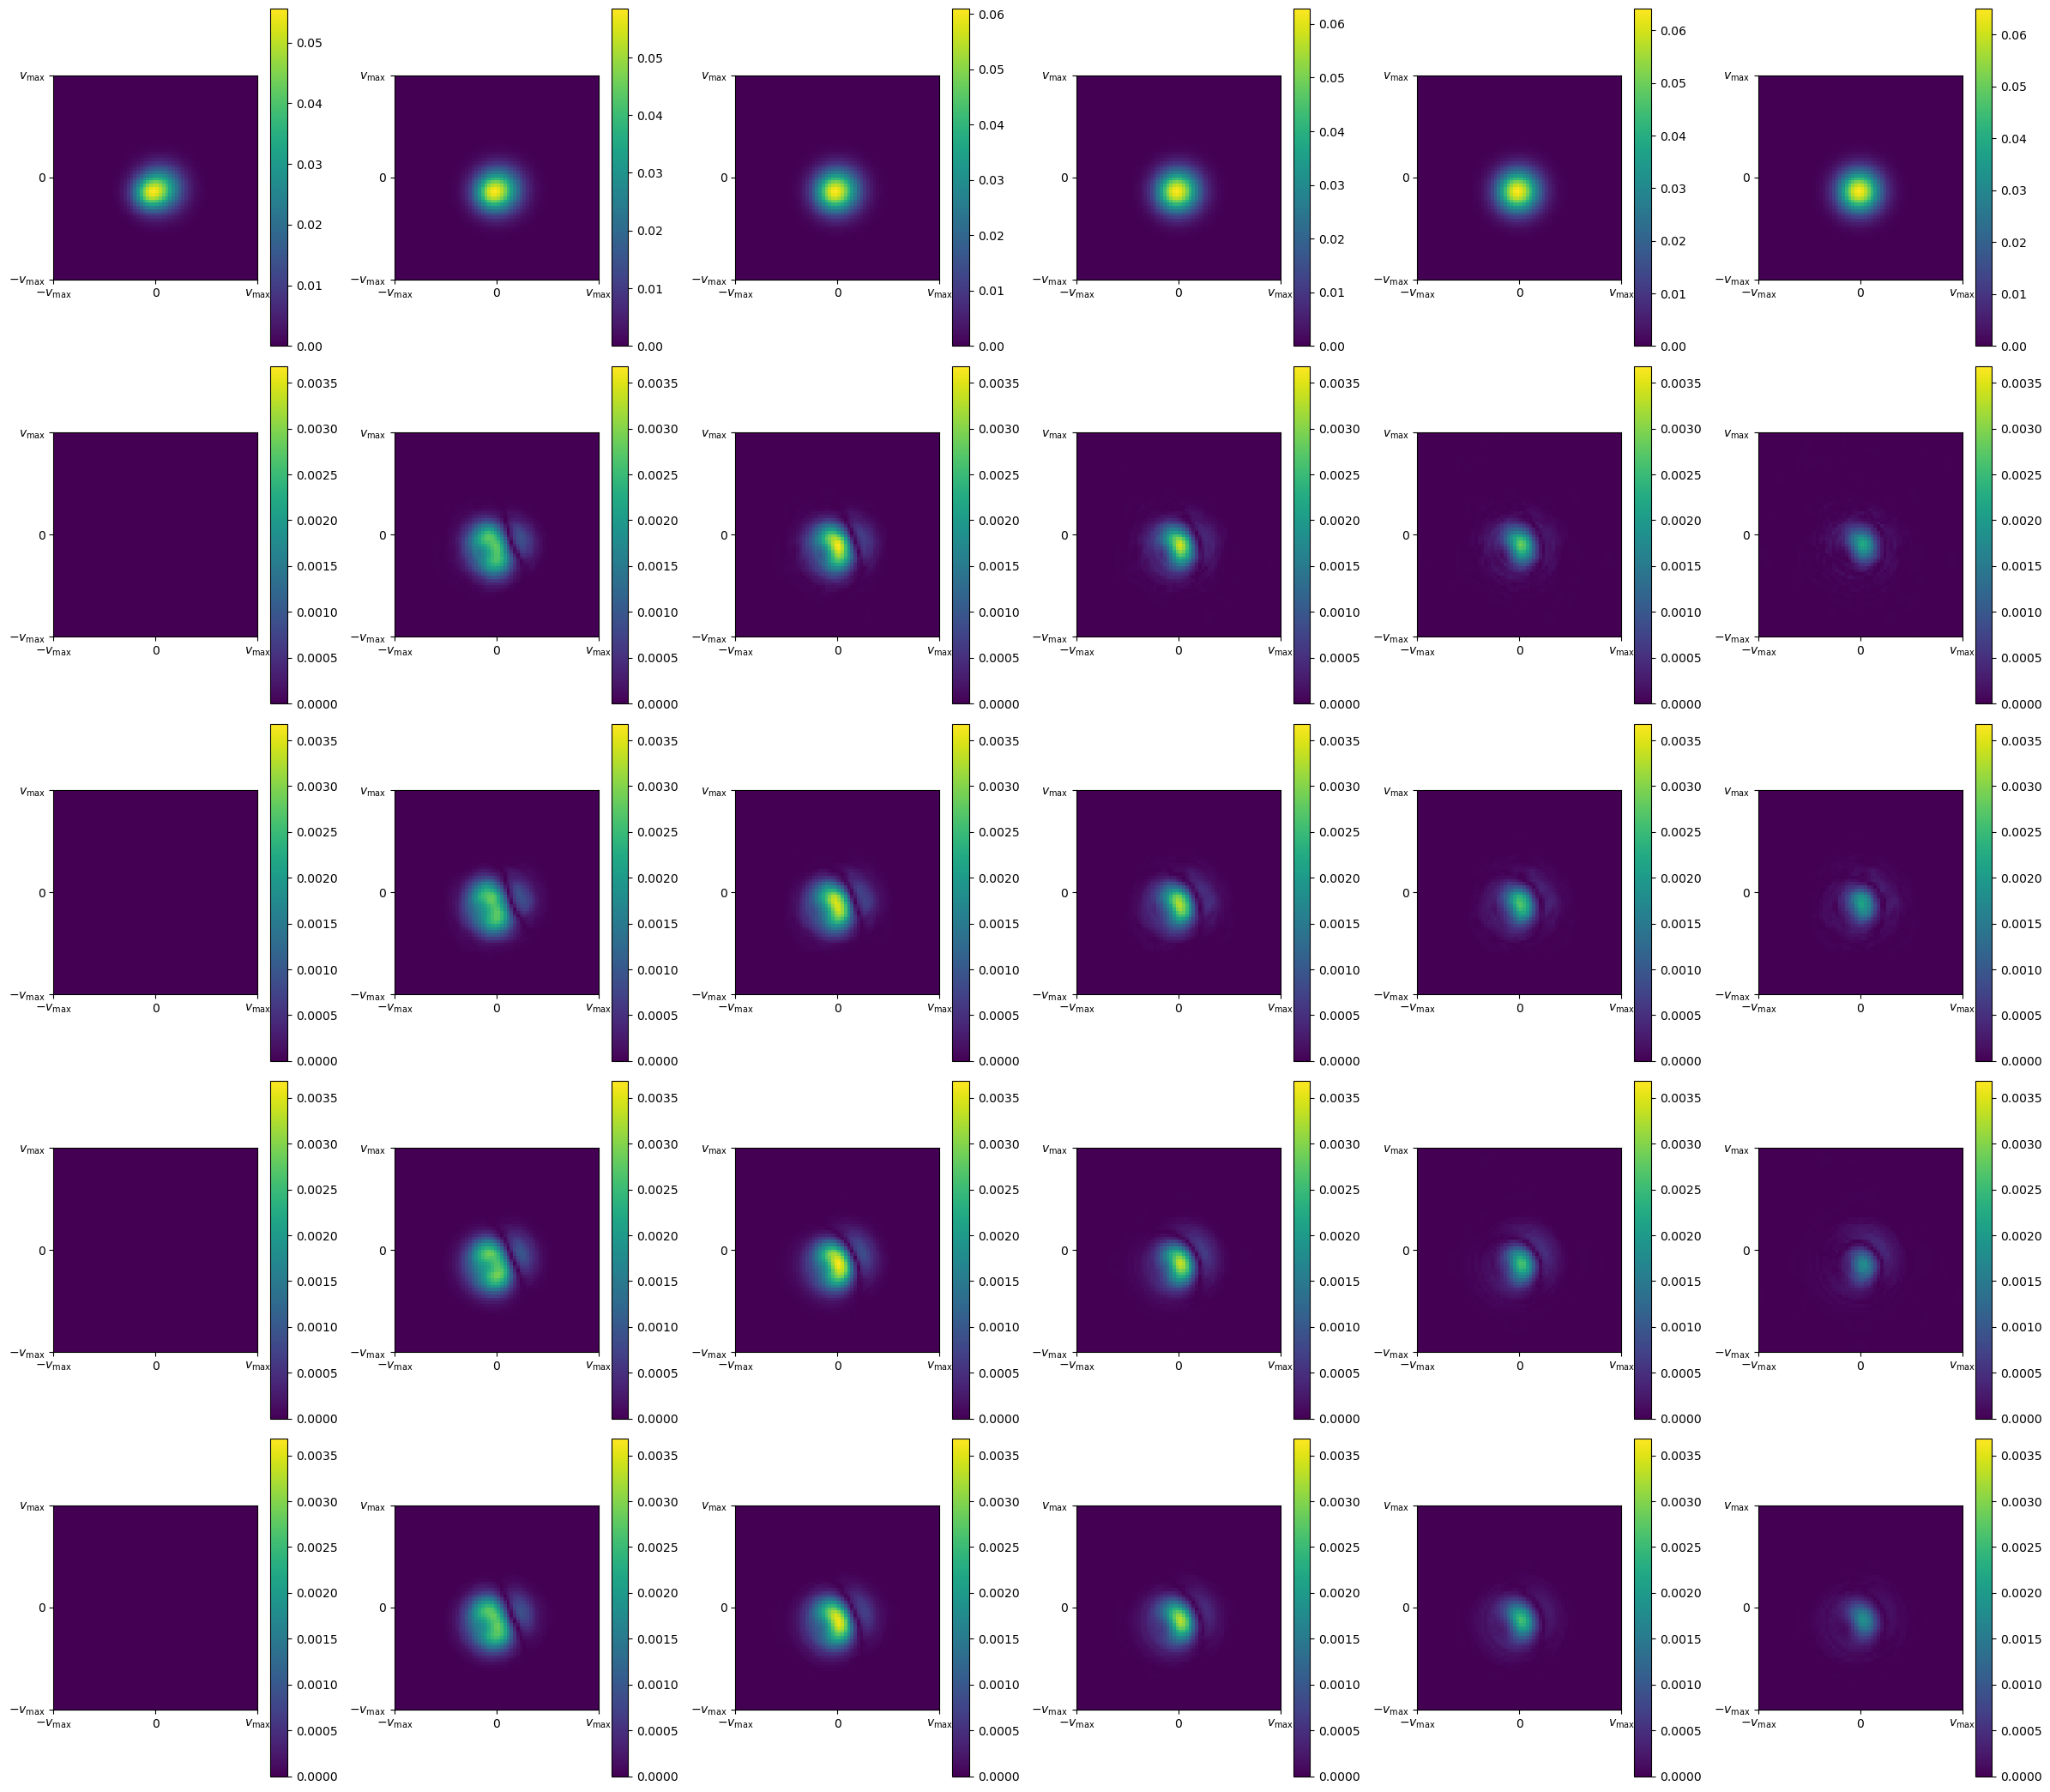

In [20]:
idx_inst = max_rel_error_fno.argmax().item()
fig:    plt.Figure
axes:   Sequence[plt.Axes]
fig, axes = plt.subplots(5, 6, figsize=(24, 21))
_cfg_imshow = {'extent': [0, 1, 0, 1], 'origin': 'lower'}
f0 = data[idx_inst, ..., res_v//2, :, :, 0].cpu()
f1 = pred_fno[idx_inst, ..., res_v//2, :, :, 0].cpu()
f2 = pred_pfno[idx_inst, ..., res_v//2, :, :, 0].cpu()
f3 = pred_rfno[idx_inst, ..., res_v//2, :, :, 0].cpu()
f4 = pred_prfno[idx_inst, ..., res_v//2, :, :, 0].cpu()
_vmax = max(
    torch.abs(f1 - f0).max().item(),
    torch.abs(f2 - f0).max().item(),
    torch.abs(f3 - f0).max().item(),
    torch.abs(f4 - f0).max().item(),
)
for c, idx_t in zip(range(6), range(0, 51, 10)):
    x0 = f0[idx_t]
    x1 = f1[idx_t]
    x2 = f2[idx_t]
    x3 = f3[idx_t]
    x4 = f4[idx_t]
    d1 = torch.abs(x1 - x0)
    d2 = torch.abs(x2 - x0)
    d3 = torch.abs(x3 - x0)
    d4 = torch.abs(x4 - x0)
    fig.colorbar(axes[0, c].imshow(x0, **_cfg_imshow))
    fig.colorbar(axes[1, c].imshow(d1, **_cfg_imshow, vmin=0.0, vmax=_vmax))
    fig.colorbar(axes[2, c].imshow(d2, **_cfg_imshow, vmin=0.0, vmax=_vmax))
    fig.colorbar(axes[3, c].imshow(d3, **_cfg_imshow, vmin=0.0, vmax=_vmax))
    fig.colorbar(axes[4, c].imshow(d4, **_cfg_imshow, vmin=0.0, vmax=_vmax))
for ax in axes.flatten():
    ax.set_xticks([0, 0.5, 1], [r"$-v_\text{max}$", "0", r"$v_\text{max}$"])
    ax.set_yticks([0, 0.5, 1], [r"$-v_\text{max}$", "0", r"$v_\text{max}$"])
fig.tight_layout()
fig.show()

In [21]:
unique_params = params.cpu().unique()
unique_params = torch.sort(unique_params)[0]
unique_params_train = unique_params[::5]
unique_params_ood   = unique_params[~torch.isin(unique_params, unique_params_train)]
def partition_rel_error(rel_error: torch.Tensor) -> list[torch.Tensor]:
    return [
        rel_error[params.cpu().squeeze(-1)==alpha]
        for alpha in unique_params
    ]


partitioned_rel_error_fno      = partition_rel_error(max_rel_error_fno)
partitioned_rel_error_pfno     = partition_rel_error(max_rel_error_pfno)
partitioned_rel_error_rfno     = partition_rel_error(max_rel_error_rfno)
partitioned_rel_error_prfno    = partition_rel_error(max_rel_error_prfno)

In [22]:
partitioned_rel_error_fno_mean = []
partitioned_rel_error_fno_std  = []
for alpha, part_fno in zip(list_alpha, partitioned_rel_error_fno):
    partitioned_rel_error_fno_mean.append(  part_fno.mean().item()  )
    partitioned_rel_error_fno_std.append(   part_fno.std().item()   )
    
partitioned_rel_error_pfno_mean = []
partitioned_rel_error_pfno_std  = []
for alpha, part_pfno in zip(list_alpha, partitioned_rel_error_pfno):
    partitioned_rel_error_pfno_mean.append(  part_pfno.mean().item()  )
    partitioned_rel_error_pfno_std.append(   part_pfno.std().item()   )
    
partitioned_rel_error_rfno_mean = []
partitioned_rel_error_rfno_std  = []
for alpha, part_rfno in zip(list_alpha, partitioned_rel_error_rfno):
    partitioned_rel_error_rfno_mean.append(  part_rfno.mean().item()  )
    partitioned_rel_error_rfno_std.append(   part_rfno.std().item()   )
    
partitioned_rel_error_prfno_mean = []
partitioned_rel_error_prfno_std  = []
for alpha, part_prfno in zip(list_alpha, partitioned_rel_error_prfno):
    partitioned_rel_error_prfno_mean.append(  part_prfno.mean().item()  )
    partitioned_rel_error_prfno_std.append(   part_prfno.std().item()   )

/tmp/ipykernel_114587/380000317.py:5: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at ../aten/src/ATen/native/ReduceOps.cpp:1808.)
  partitioned_rel_error_fno_std.append(   part_fno.std().item()   )
/tmp/ipykernel_114587/380000317.py:11: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at ../aten/src/ATen/native/ReduceOps.cpp:1808.)
  partitioned_rel_error_pfno_std.append(   part_pfno.std().item()   )
/tmp/ipykernel_114587/380000317.py:17: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at ../aten/src/ATen/native/ReduceOps.cpp:1808.)
  partitioned_rel_error_rfno_std.append(   part_rfno.std().item()   )
/tmp/ipykernel_114587/

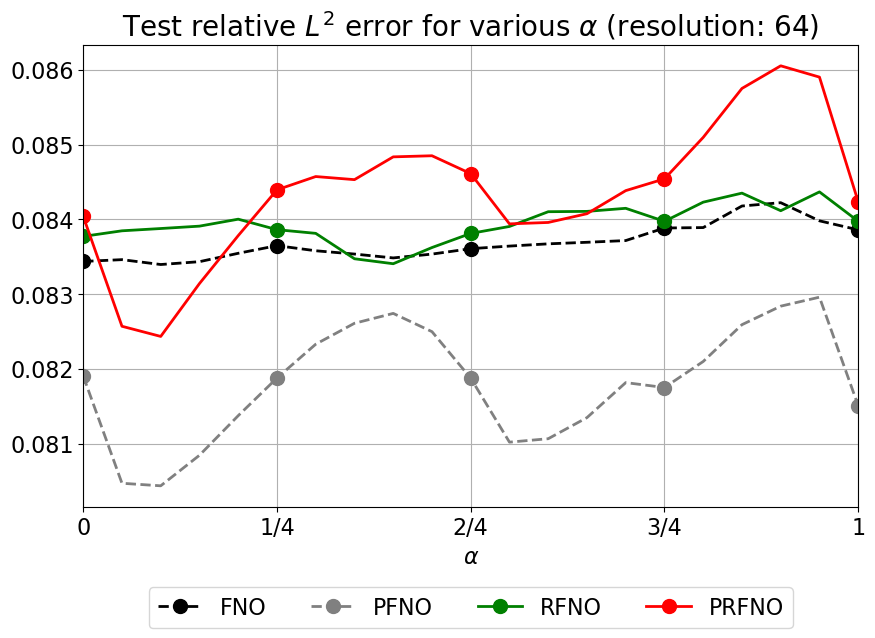

In [27]:
plt.figure(figsize=(10, 6))
plt.title(rf"Test relative $L^2$ error for various $\alpha$ (resolution: {res_v})", fontsize=SIZE_TITLE)
for list_mean, list_std, _color, _ls, _lbl in zip(
        [
            partitioned_rel_error_fno_mean,
            partitioned_rel_error_pfno_mean,
            partitioned_rel_error_rfno_mean,
            partitioned_rel_error_prfno_mean,
        ],
        [
            partitioned_rel_error_fno_std,
            partitioned_rel_error_pfno_std,
            partitioned_rel_error_rfno_std,
            partitioned_rel_error_prfno_std,
        ],
        LIST_COLOR_2,
        LIST_LINESTYLE,
        LIST_LABELS
    ):
    plt.plot(
        unique_params, list_mean,
        color=_color, linestyle=_ls, linewidth=LINEWIDTH_2,
        label=_lbl,
        marker='o', markevery=5, markersize=MARKERSIZE,
    )
    # plt.errorbar(
    #     unique_params, list_mean,
    #     yerr=list_std,
    #     color=_color, linestyle=_ls, linewidth=LINEWIDTH_2,
    #     label=_lbl,
    #     marker='o', markevery=5, markersize=MARKERSIZE,
    #     capsize=MARKERSIZE/2, capthick=2,
    # )

plt.xlim(unique_params.min().item(), unique_params.max().item())
# plt.ylim(0, 5e-2)
plt.xlabel(r"$\alpha$", fontsize=SIZE_LABEL)
# plt.ylabel("Relative $L^2$ error", fontsize=SIZE_LABEL)
# plt.yscale('log')
plt.xticks(unique_params_train, list(map(lambda x: f"{int(4*x)}/4" if 0<x and x<1 else f"{int(x)}", unique_params_train)))
# plt.yticks([k*1e-2 for k in range(1, 6)], [rf"${k} \times 10^{{-2}}$" for k in range(1, 6)])
plt.tick_params(axis='both', which='both', labelsize=SIZE_TICK)
plt.legend(bbox_to_anchor=(0.5, -0.15), loc='upper center', fontsize=SIZE_LABEL, ncol=4)
plt.grid()
plt.savefig(f"test_error_vs_alpha__[max_freq{max_freq:02d}__seed{seed}]__res{res_v:03d}.pdf", bbox_inches='tight')

End of file